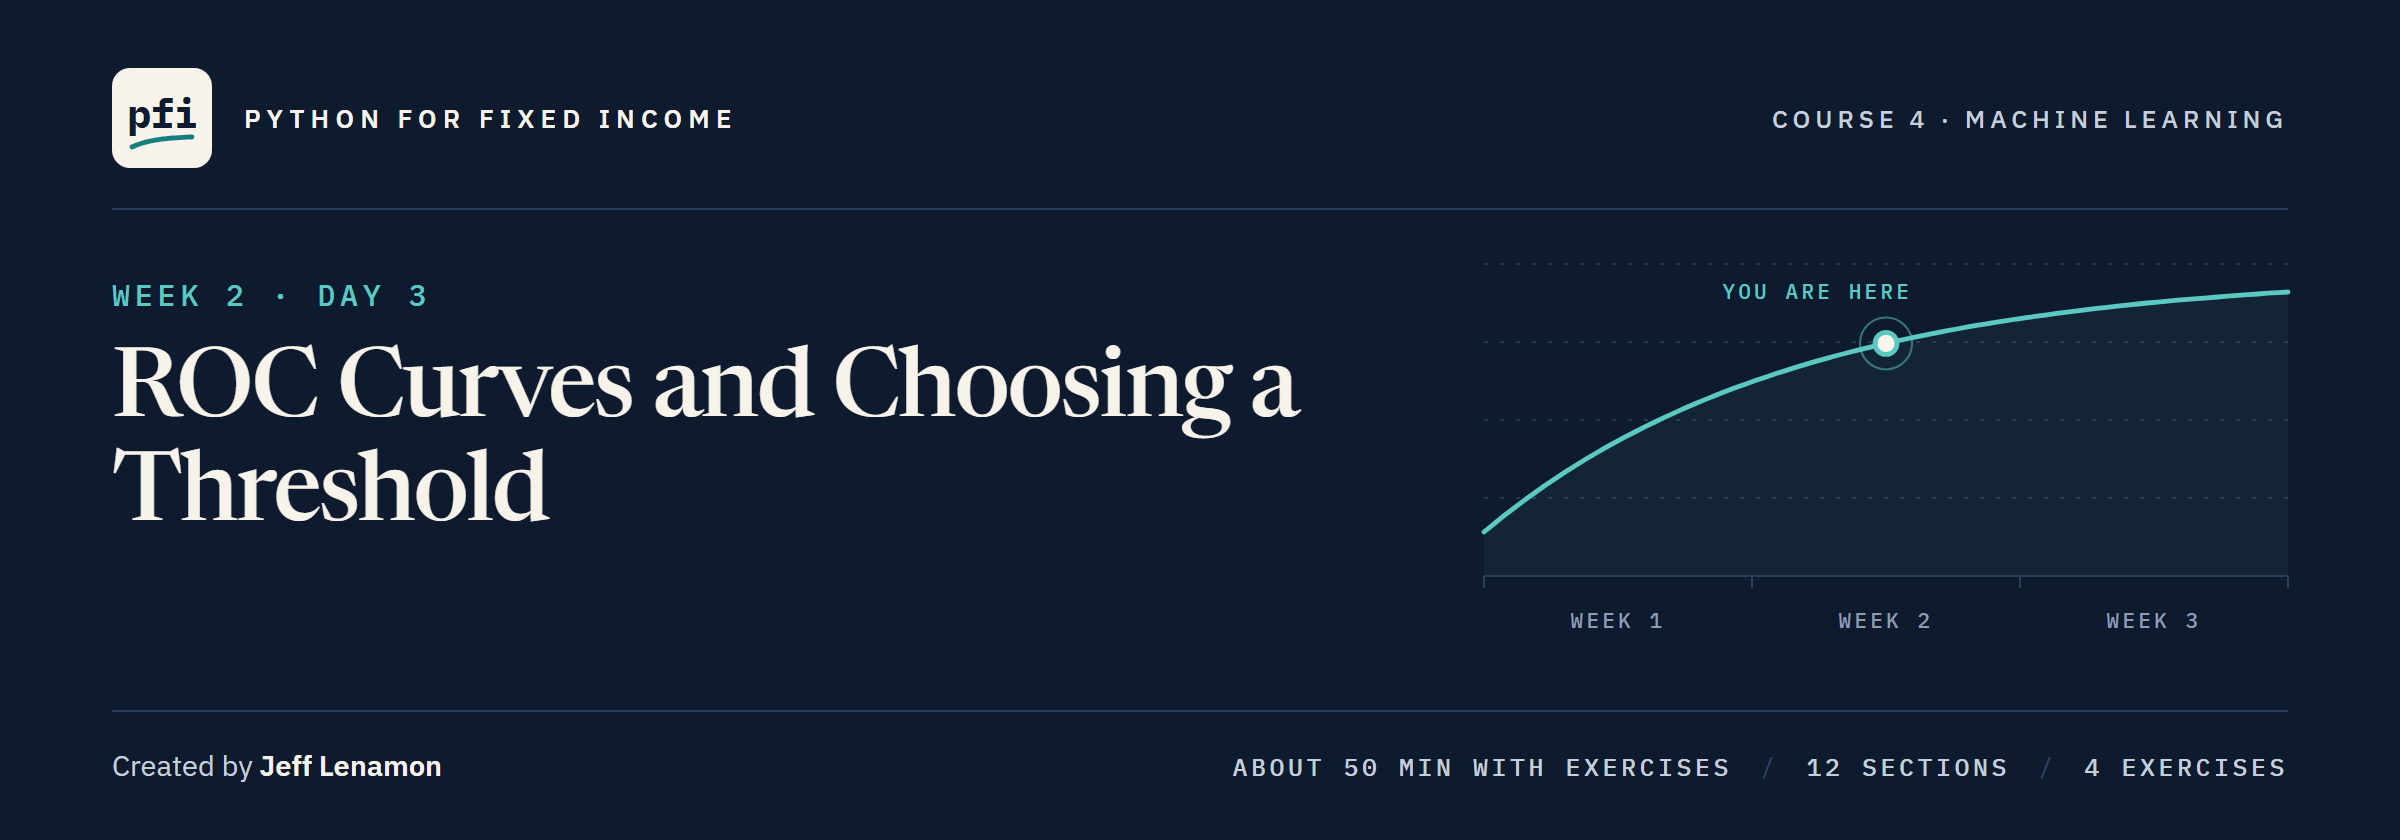

# ROC Curves and Choosing a Threshold

Week 2, Day 3. See every threshold at once with ROC and precision-recall curves, score the ranking with AUC, and choose one threshold on validation accounts by a rule written down first.

**Data:** `credit_card_default.csv`, 30,000 card accounts in Taiwan in 2005: **real**, UCI Machine Learning Repository dataset 350, CC BY 4.0. Citation: Yeh, I. (2009). Default of Credit Card Clients [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week2/day3/08_roc_curves_and_choosing_a_threshold.ipynb)

# Problem Statement

## Business Context

Day 7 ended with a model that flags a quarter of the defaults at 0.5, and a 0.5 that is ours to move.
Every threshold makes a different list of accounts to review, and nothing in the file says which list is right.
Today the desk sees all of those lists at once, scores the ranking behind them, and chooses one threshold by a rule written down before looking.
The file is Day 6's: 30,000 real card accounts in Taiwan in 2005, so nothing here carries over to another market or year.
`SEX`, `EDUCATION`, `MARRIAGE` and `AGE` are never features: a model using them would sort people by them, and leaving them out does not make a model neutral, because other columns can carry the same information.
A flag means "flagged at threshold t", never a credit decision about anyone.

## Objectives

Draw the ROC curve by hand and with scikit-learn, score the whole curve with AUC and see what it reads, draw the precision-recall curve, choose a threshold on validation accounts by a stated rule, show why the accounts that choose cannot report, and read one calibration chart.

## Data Dictionary

`credit_card_default.csv`, as on Days 6 and 7, one row per account:

1. `ID`: a row label, never a feature
2. `LIMIT_BAL`: the credit limit, NT dollars
3. `PAY_0`, `PAY_2` to `PAY_6`: repayment status, September back to April
4. `BILL_AMT1` to `BILL_AMT6`: the bill, NT dollars
5. `PAY_AMT1` to `PAY_AMT6`: the amount paid, NT dollars
6. `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`: about the person, never features
7. `default payment next month`: 1 if the account defaulted the following month, 0 if not, **the target**

## Your Route Through Day 3

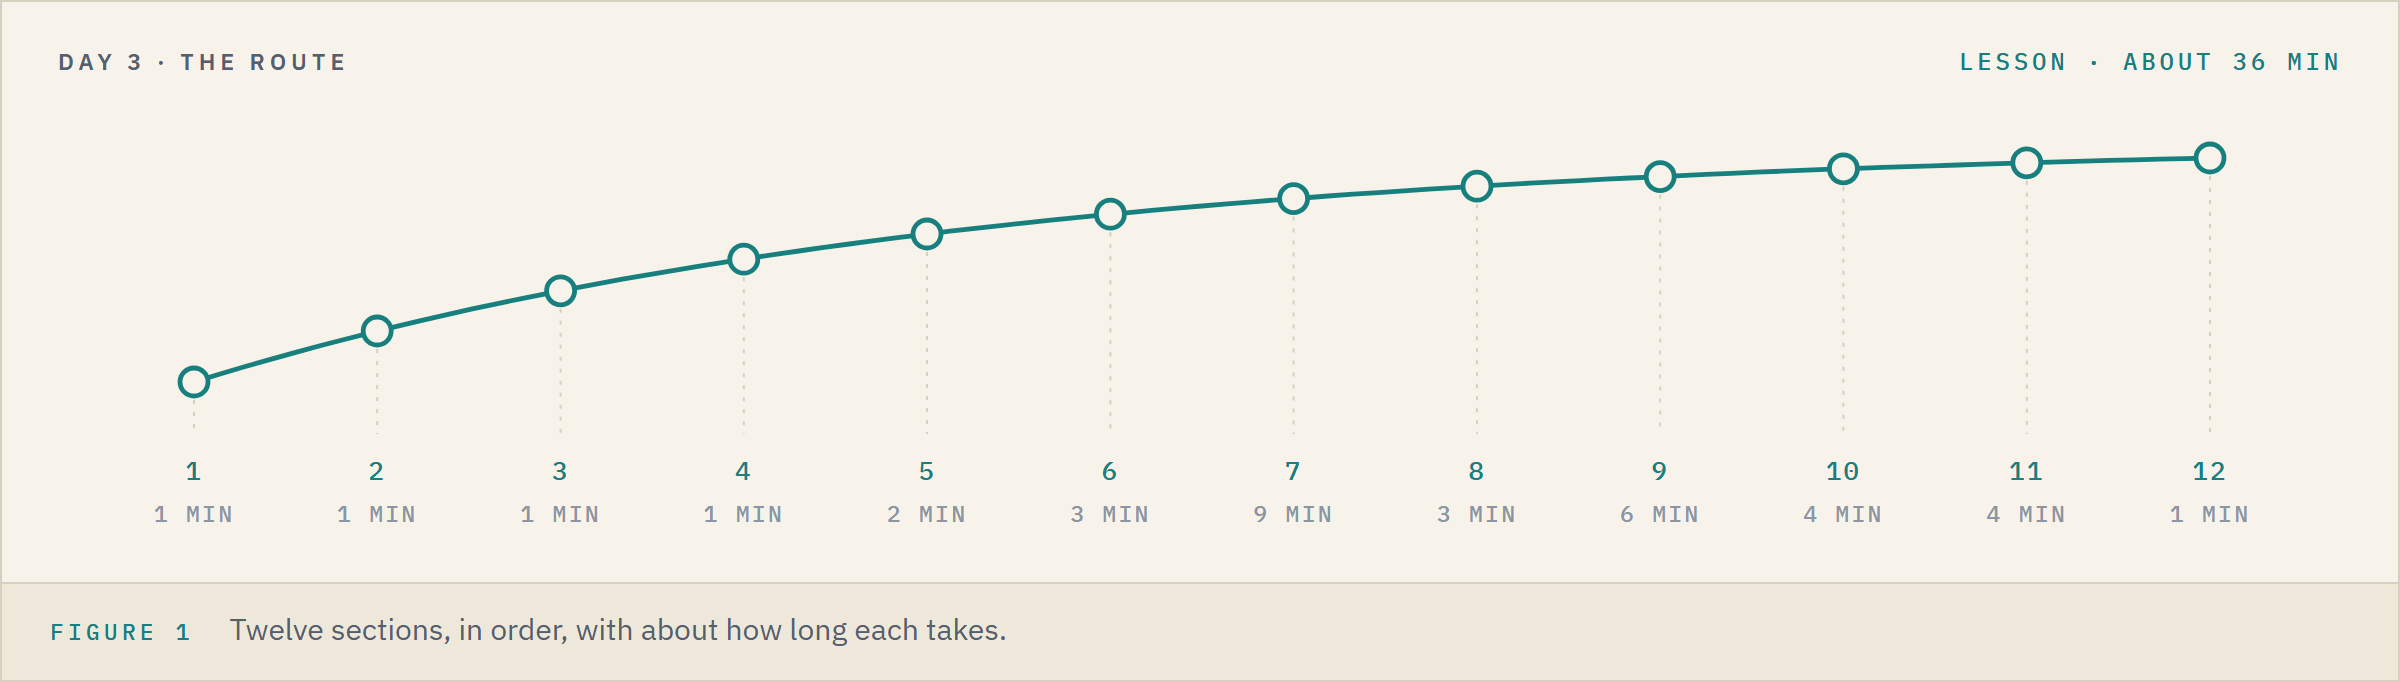

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">1</td><td align="left">Setting Up</td><td align="left">1 min</td></tr>
<tr><td align="left">2</td><td align="left">Loading the Data</td><td align="left">1 min</td></tr>
<tr><td align="left">3</td><td align="left">Data Overview</td><td align="left">1 min</td></tr>
<tr><td align="left">4</td><td align="left">Data Preparation for Modeling</td><td align="left">1 min</td></tr>
<tr><td align="left">5</td><td align="left">Model Building</td><td align="left">2 min</td></tr>
<tr><td align="left">6</td><td align="left">The ROC Curve</td><td align="left">3 min</td></tr>
<tr><td align="left">7</td><td align="left">AUC: One Number for the Curve</td><td align="left">9 min</td></tr>
<tr><td align="left">8</td><td align="left">The Precision-Recall Curve</td><td align="left">3 min</td></tr>
<tr><td align="left">9</td><td align="left">Choosing a Threshold</td><td align="left">6 min</td></tr>
<tr><td align="left">10</td><td align="left">Model Performance Comparison</td><td align="left">4 min</td></tr>
<tr><td align="left">11</td><td align="left">Calibration</td><td align="left">4 min</td></tr>
<tr><td align="left">12</td><td align="left">Insights and Conclusion</td><td align="left">1 min</td></tr>
</table>
<br clear="left">

**Time.** About 36 minutes for the lesson, then about 12 for the four exercises.

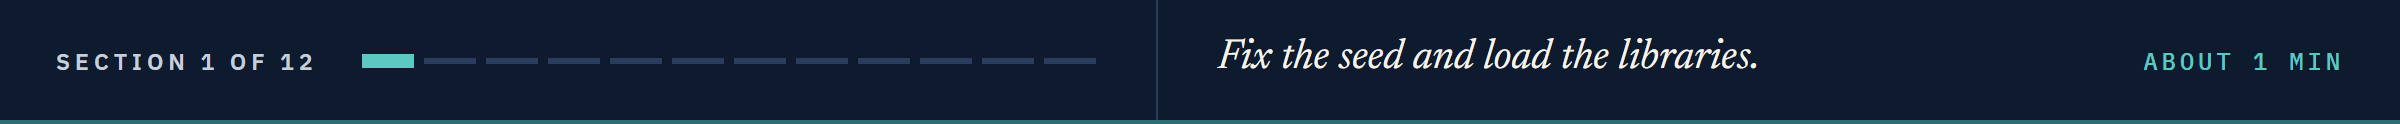

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and the slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to split the accounts and fit Day 6's model
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# to score flags, rankings and probabilities
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score, auc
from sklearn.calibration import calibration_curve

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:,.4f}".format)

# one colour for each of the four kinds of account a confusion matrix counts, the same on Days 7 to 10
CELL_COLOURS = {"TN": "#56B4E9", "FP": "#DE8F05", "FN": "#D55E00", "TP": "#0173B2"}

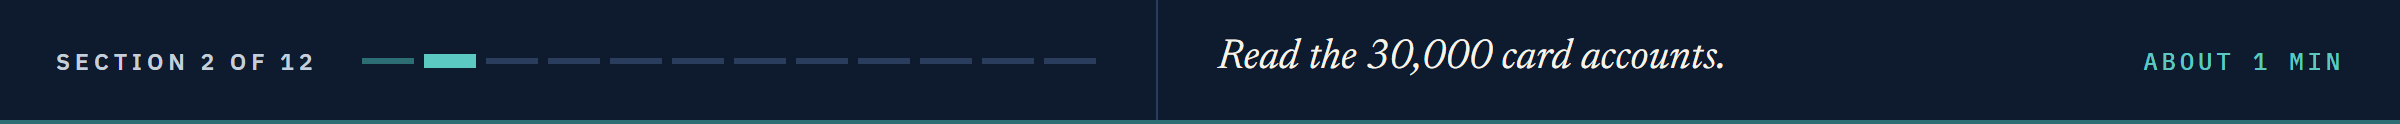

# Loading the Data

## Reading the Card Accounts

In [3]:
# the 30,000 card accounts
card = pd.read_csv(DATA + "credit_card_default.csv")

# the target's name has spaces, so we keep it in a variable
TARGET = "default payment next month"

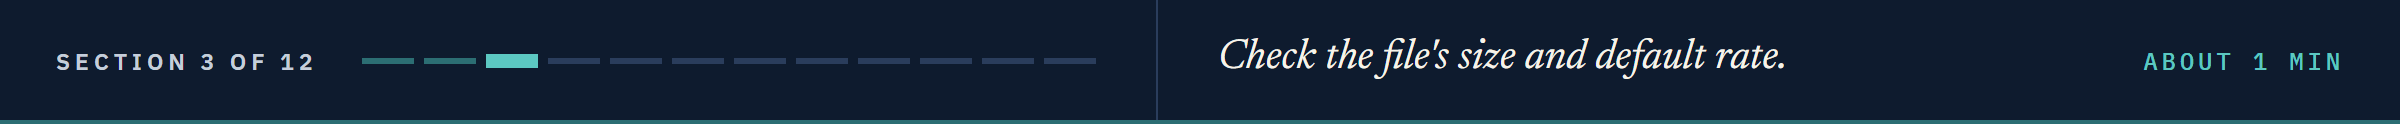

# Data Overview

## Checking the Shape and the Default Rate

In [4]:
# the file's size, and how many accounts defaulted
print(card.shape)
print(card[TARGET].sum(), "accounts defaulted:", round(card[TARGET].mean() * 100, 2), "percent")

(30000, 25)
6636 accounts defaulted: 22.12 percent


30,000 accounts and 25 columns; 6,636 defaulted, 22.12 percent.

**The file is Day 6's and passed Day 6's checks, so we go straight to the split.**

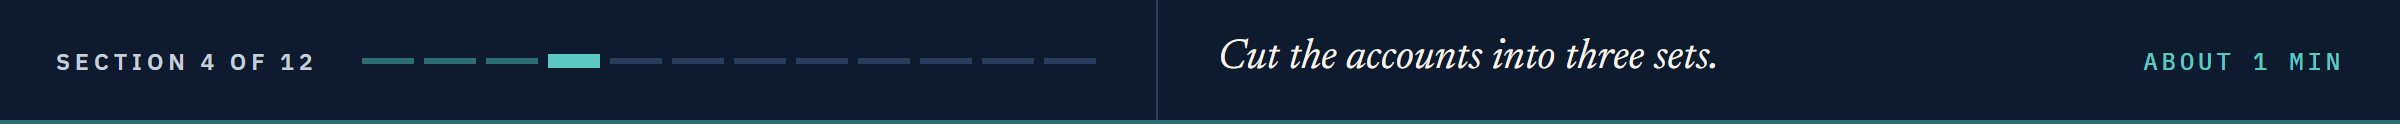

# Data Preparation for Modeling

## Choosing the Features and the Target

In [5]:
# the four columns about the person are never features, and ID is only a row label
PERSON_COLUMNS = ["SEX", "EDUCATION", "MARRIAGE", "AGE"]
FEATURES = [column for column in card.columns if column not in ["ID", TARGET] + PERSON_COLUMNS]
X = card[FEATURES]
y = card[TARGET]
print(len(FEATURES), "features")

19 features


## Splitting Into Training, Validation and Test Accounts

Day 6's two calls with the same seed, so the same accounts land in each part.

In [6]:
# a fifth of the accounts become test accounts, then a quarter of the rest become validation accounts
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=SEED)
print("Training:", len(X_train), " Validation:", len(X_valid), " Test:", len(X_test))
print("Defaults in validation:", y_valid.sum(), " Paid in validation:", (y_valid == 0).sum())

Training: 18000  Validation: 6000  Test: 6000
Defaults in validation: 1327  Paid in validation: 4673


**Fit on training accounts, choose on validation accounts; the test accounts stay closed until Day 10.**

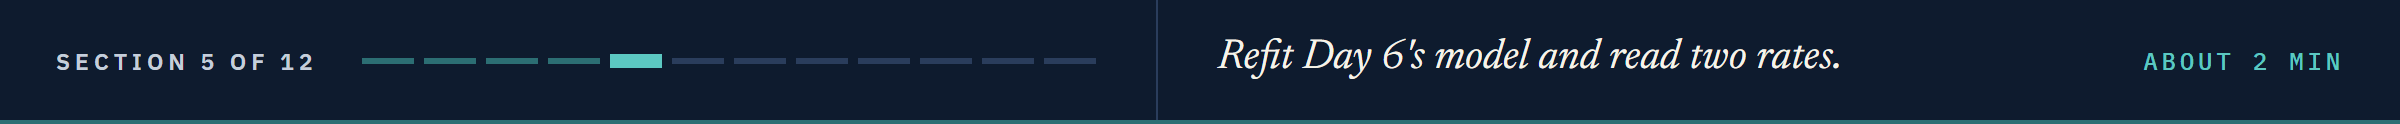

# Model Building

## Day 6's Model, Fitted Again

Q. How many different probabilities does the model give the 6,000 validation accounts?

In [7]:
# scale every column, then fit the logistic regression, as one pipeline: Day 6's model for the week
model = Pipeline([("scale", StandardScaler()), ("logit", LogisticRegression(max_iter=1000))])
model.fit(X_train, y_train)

# the model probability of default for every validation account, and how many distinct values there are
proba_valid = model.predict_proba(X_valid)[:, 1]
print("Accounts:", len(proba_valid), " Distinct probabilities:", pd.Series(proba_valid).nunique())

Accounts: 6000  Distinct probabilities: 5882


5,882 distinct probabilities: a few accounts repeat another row and share its probability.

Each distinct probability is a threshold that makes a different list.

## Two Rates at One Threshold

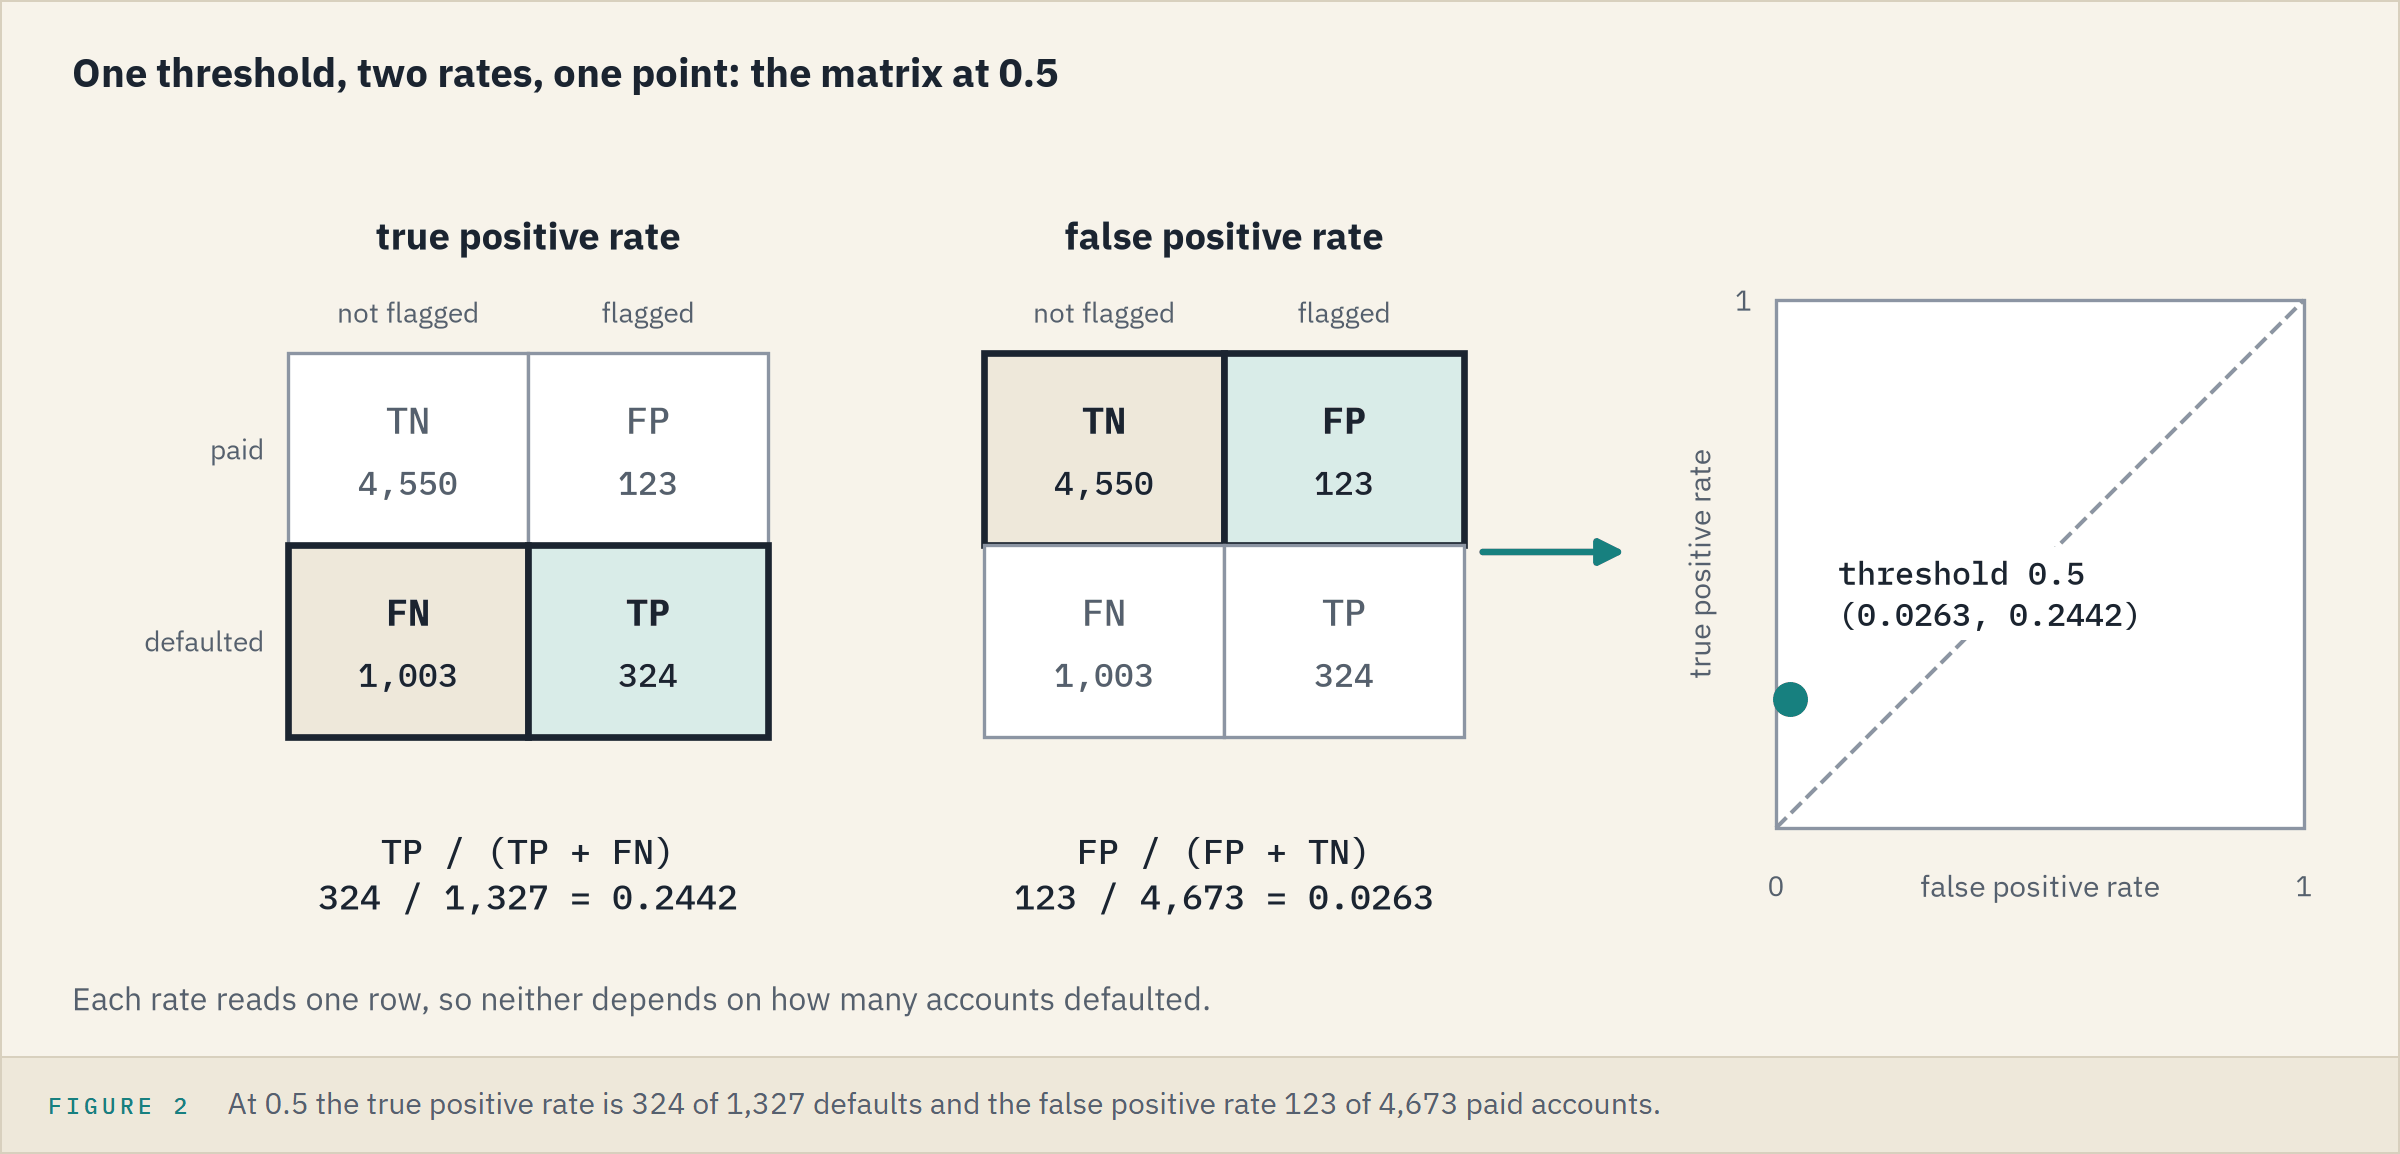

The **true positive rate** (TPR) is the share of defaults flagged: recall under a second name.

The **false positive rate** (FPR) is the share of paid accounts flagged.

Each reads one row of the matrix, so neither moves with how many accounts defaulted.

In [8]:
# the four counts at 0.5, then the two rates
tn, fp, fn, tp = confusion_matrix(y_valid, proba_valid >= 0.5).ravel()
print("True positive rate:", round(tp / (tp + fn), 4), " False positive rate:", round(fp / (fp + tn), 4))

True positive rate: 0.2442  False positive rate: 0.0263


**One threshold gives one point on a chart of these two rates; every threshold gives a curve.**

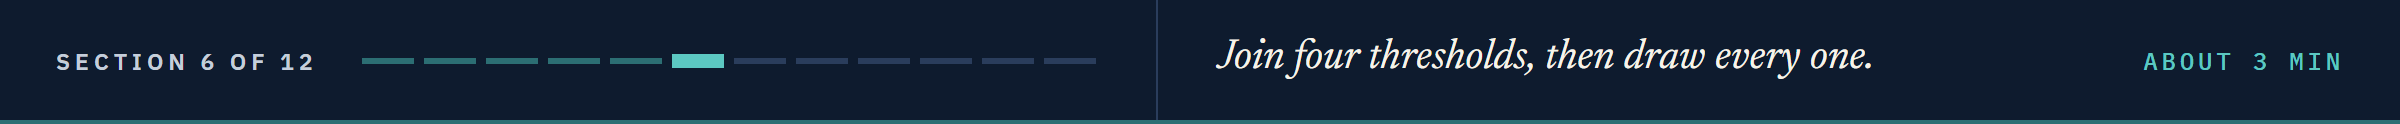

# The ROC Curve

## Four Thresholds by Hand

Q. Where do Day 7's four thresholds land on a chart of the two rates?

In [9]:
# the two rates at Day 7's four thresholds, one row each
points = []
for threshold in [0.7, 0.5, 0.25, 0.1]:
    cell_counts = confusion_matrix(y_valid, proba_valid >= threshold).ravel()  # TN, FP, FN, TP
    points.append({"threshold": threshold, "flagged": cell_counts[1] + cell_counts[3],
                   "FPR": cell_counts[1] / (cell_counts[0] + cell_counts[1]), "TPR": cell_counts[3] / (cell_counts[2] + cell_counts[3])})
by_hand = pd.DataFrame(points)
by_hand

,threshold,flagged,FPR,TPR
0,0.7000,74,0.0051,0.0377
1,0.5000,447,0.0263,0.2442
2,0.2500,1437,0.1556,0.5350
3,0.1000,4848,0.7813,0.9020


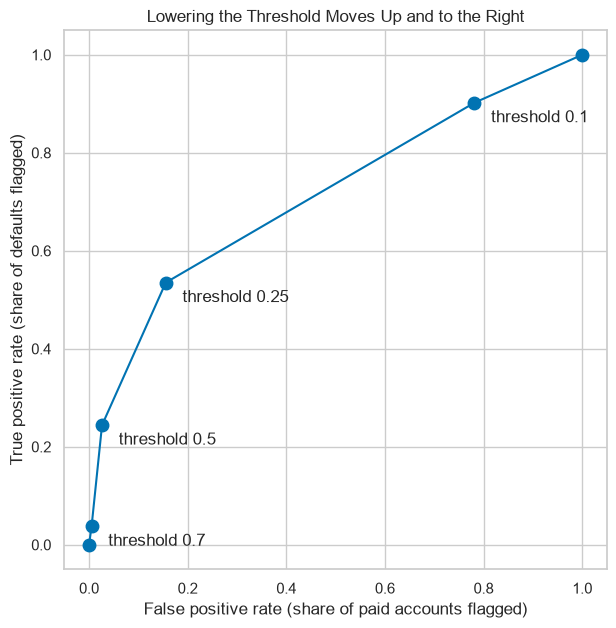

In [10]:
# the four points joined, from flagging nobody at (0, 0) to flagging everyone at (1, 1)
plt.figure(figsize=(7, 7))
plt.plot([0] + list(by_hand["FPR"]) + [1], [0] + list(by_hand["TPR"]) + [1], marker="o", markersize=9)
for threshold, x, y_point in zip(by_hand["threshold"], by_hand["FPR"], by_hand["TPR"]):
    plt.annotate("threshold " + str(threshold), (x, y_point), xytext=(12, -14), textcoords="offset points")
plt.xlabel("False positive rate (share of paid accounts flagged)")
plt.ylabel("True positive rate (share of defaults flagged)")
plt.title("Lowering the Threshold Moves Up and to the Right")
plt.show()

Each step down in threshold flags more defaults and more paid accounts, so the point moves up and to the right.

From 0.25 to 0.1 the true positive rate rises by 0.367 and the false positive rate by 0.626: the last defaults are expensive.

True positive rate against false positive rate, one point per threshold, is a **ROC curve** (receiver operating characteristic).

## Every Threshold With `roc_curve`

`roc_curve` computes both rates at every distinct probability, highest first.

`drop_intermediate=False` keeps every one, because its default drops points on straight runs of the curve.

In [11]:
# both rates at every threshold the model's probabilities allow
fpr, tpr, roc_thresholds = roc_curve(y_valid, proba_valid, drop_intermediate=False)
print("Thresholds:", len(roc_thresholds), " The first:", roc_thresholds[0])

Thresholds: 5883  The first: inf


5,883 thresholds: each distinct probability, plus `inf` first, which flags nobody and gives the point (0, 0).

`c=` gives each dot a number to colour it by, and `plt.colorbar` draws the key to those colours.

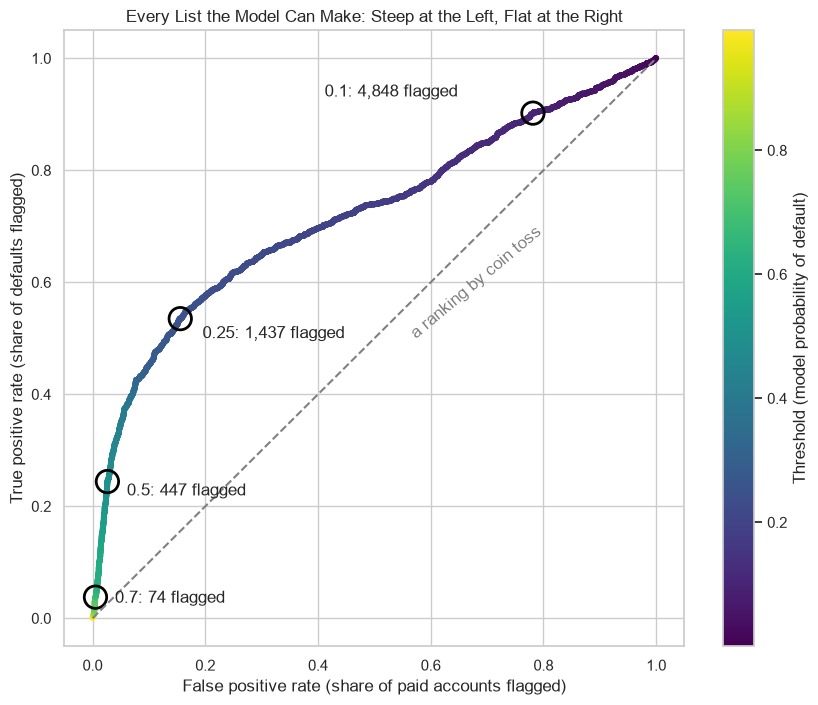

In [12]:
# the showpiece: every list the model can make, one dot each, coloured by its threshold ([1:] skips inf, which has no colour)
plt.figure(figsize=(10, 8))
plt.scatter(fpr[1:], tpr[1:], c=roc_thresholds[1:], cmap="viridis", s=10)
plt.colorbar(label="Threshold (model probability of default)")
# Day 7's four thresholds, ringed and labelled with the accounts each one flags
plt.scatter(by_hand["FPR"], by_hand["TPR"], s=260, facecolor="none", edgecolor="black", linewidth=2)  # facecolor="none": rings, not dots
for threshold, flagged, x, y_point, offset in zip(by_hand["threshold"], by_hand["flagged"], by_hand["FPR"], by_hand["TPR"], [(14, -4), (14, -10), (16, -14), (-150, 12)]):
    plt.annotate(f"{threshold}: {flagged:,} flagged", (x, y_point), xytext=offset, textcoords="offset points", fontsize=12)
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.text(0.56, 0.5, "a ranking by coin toss", color="gray", rotation=40, fontsize=12)
plt.xlabel("False positive rate (share of paid accounts flagged)")
plt.ylabel("True positive rate (share of defaults flagged)")
plt.title("Every List the Model Can Make: Steep at the Left, Flat at the Right")
plt.show()

Day 7's four points sit on the curve: each is one of the 5,883 lists.

The curve climbs steeply at the left: the first accounts flagged are mostly defaults.

It flattens at the right: there the next accounts flagged are mostly paid.

The colour says which threshold makes each list.

**One curve holds every list; one number can score the whole curve.**

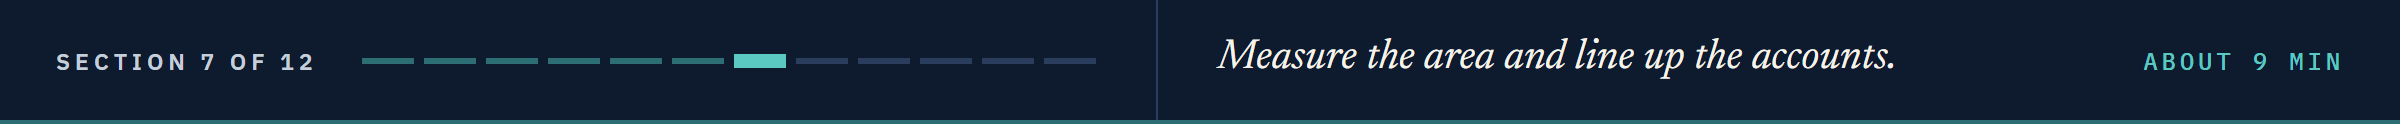

# AUC: One Number for the Curve

## The Area Under the Curve

The area under the ROC curve, **AUC**, scores the whole curve in one number.

The diagonal gives 0.5, and a curve that climbs straight to the top left corner gives 1.

Q. What is the model's ROC AUC on the validation accounts, and on the accounts it was fitted on?

In [13]:
# AUC from the probabilities: no threshold is needed (:.4f prints four decimals, trailing zeros kept)
print(f"Validation ROC AUC: {roc_auc_score(y_valid, proba_valid):.4f}")
print(f"Training ROC AUC:   {roc_auc_score(y_train, model.predict_proba(X_train)[:, 1]):.4f}")

Validation ROC AUC: 0.7190
Training ROC AUC:   0.7296


0.7190 on validation against 0.7296 on training: close, so the ranking holds up on unseen accounts.

**Predict 1**

Q. Give `roc_curve` the 0/1 flags at 0.5 instead of the probabilities. Sketch the curve it draws.

In [14]:
# the flags at 0.5 hold only two values, so roc_curve finds only two thresholds and the start
flags_50 = (proba_valid >= 0.5).astype(int)
flag_fpr, flag_tpr, flag_thresholds = roc_curve(y_valid, flags_50)
print("Points:", len(flag_thresholds), " FPR:", flag_fpr.round(4), " TPR:", flag_tpr.round(4))
print("ROC AUC of the flags:", round(roc_auc_score(y_valid, flags_50), 4))

Points: 3  FPR: [0.     0.0263 1.    ]  TPR: [0.     0.2442 1.    ]
ROC AUC of the flags: 0.6089


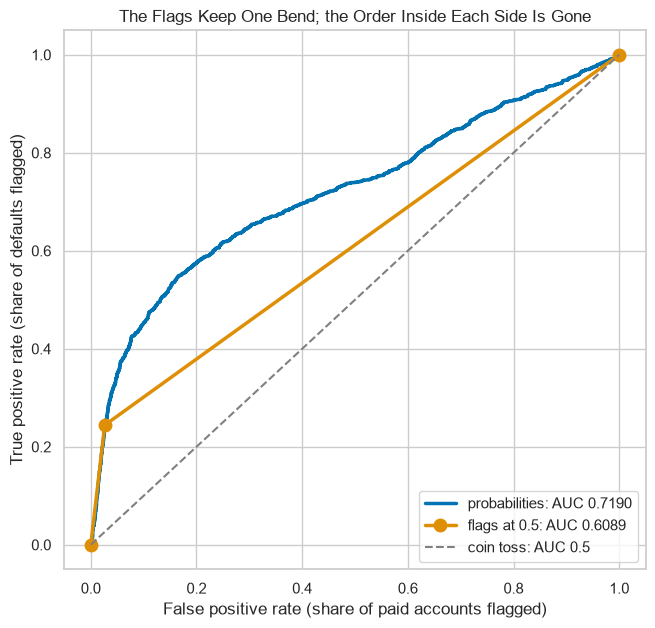

In [15]:
# the ranking against the flags, the area of each in the key
plt.figure(figsize=(7.5, 7))
plt.plot(fpr, tpr, linewidth=2.5, label="probabilities: AUC 0.7190")
plt.plot(flag_fpr, flag_tpr, marker="o", markersize=9, linewidth=2.5, label="flags at 0.5: AUC 0.6089")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="coin toss: AUC 0.5")
plt.xlabel("False positive rate (share of paid accounts flagged)")
plt.ylabel("True positive rate (share of defaults flagged)")
plt.title("The Flags Keep One Bend; the Order Inside Each Side Is Gone")
plt.legend(loc="lower right")
plt.show()

Three points and one bend, at (0.0263, 0.2442): the flags remember only which side of 0.5 each account fell on.

The order inside each side is gone, and with it 0.11 of AUC.

**AUC is always computed on probabilities, never on flags.**

## Squaring Every Probability

**Predict 2**

Q. Square every probability, so 0.5 becomes 0.25 and 0.1 becomes 0.01. What is the ROC AUC of `proba_valid ** 2`?

In [16]:
# the same accounts, every probability squared
print(f"ROC AUC of the squared probabilities: {roc_auc_score(y_valid, proba_valid ** 2):.4f}")

ROC AUC of the squared probabilities: 0.7190


0.7190, unchanged.

Squaring moves every number and keeps every account in the same order.

## AUC as a Share of Pairs

Take one account that defaulted and one that paid: the ranking gets the pair right when the defaulter has the higher probability.

Q. Over every such pair, what share does the ranking get right?

In [17]:
# the probabilities of the defaulters, highest first, and of the paid accounts, lowest first
proba_def = np.sort(proba_valid[y_valid == 1])[::-1]
proba_paid = np.sort(proba_valid[y_valid == 0])
print("Pairs:", len(proba_def) * len(proba_paid))

Pairs: 6201071


`[:, None]` turns the 1,327 defaulters into a column and `[None, :]` turns the 4,673 paid accounts into a row, so comparing the two compares every pair at once: a 1,327 by 4,673 grid of True and False.

In [18]:
# True where the defaulter scored higher than the paid account; a tie counts half
higher = proba_def[:, None] > proba_paid[None, :]
tied = proba_def[:, None] == proba_paid[None, :]
print(f"Share of pairs ranked the right way: {higher.mean() + 0.5 * tied.mean():.4f}")
print("Tied pairs:", tied.sum())

Share of pairs ranked the right way: 0.7190
Tied pairs: 137


The share of pairs ranked the right way is the AUC, 0.7190.

Only 137 of the 6,201,071 pairs tie, too few to move the fourth decimal.

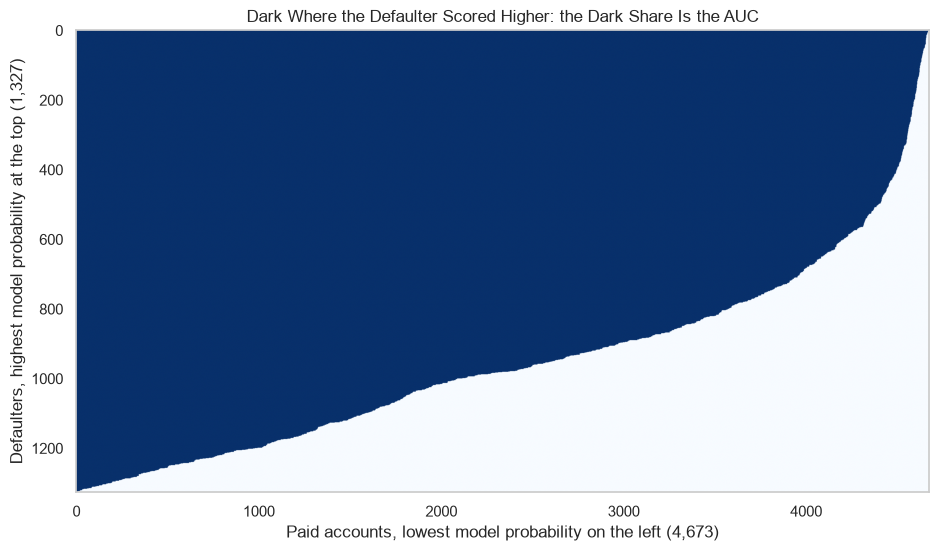

In [19]:
# the pair grid: one row per defaulter, one column per paid account, dark where the defaulter scored higher
plt.figure(figsize=(11, 6))
plt.imshow(higher, aspect="auto", cmap="Blues")  # imshow draws a grid as a picture; aspect="auto" lets it fill the frame
plt.xlabel("Paid accounts, lowest model probability on the left (4,673)")
plt.ylabel("Defaulters, highest model probability at the top (1,327)")
plt.title("Dark Where the Defaulter Scored Higher: the Dark Share Is the AUC")
plt.grid(False)
plt.show()

The dark share of the grid is 0.7190 of its area.

Give the grid a half turn and its edge is the ROC curve: each paid account is a threshold, and the dark run in its column is the share of defaulters above it.

AUC reads only the order of the probabilities, which is why squaring changed nothing.

In [20]:
# reverse the order: the lowest probability first
print(f"ROC AUC of 1 - probability: {roc_auc_score(y_valid, 1 - proba_valid):.4f}")

ROC AUC of 1 - probability: 0.2810


Reversed, the ranking gets 0.2810 of the pairs right, and 0.7190 plus 0.2810 is 1.

## The Ranking as a Barcode

A **rank barcode** lines the 6,000 accounts up by probability, lowest on the left, with a tick for each default.

In [21]:
# the accounts in order of probability, numbered 0 (lowest) to 5,999 (highest)
scores = pd.DataFrame({"defaulted": y_valid.to_numpy(), "proba": proba_valid})
ranked = scores.sort_values("proba").reset_index(drop=True)
places = ranked.index[ranked["defaulted"] == 1]
print("Defaults in the upper half:", (places >= 3000).sum(), " in the lower half:", (places < 3000).sum())

Defaults in the upper half: 949  in the lower half: 378


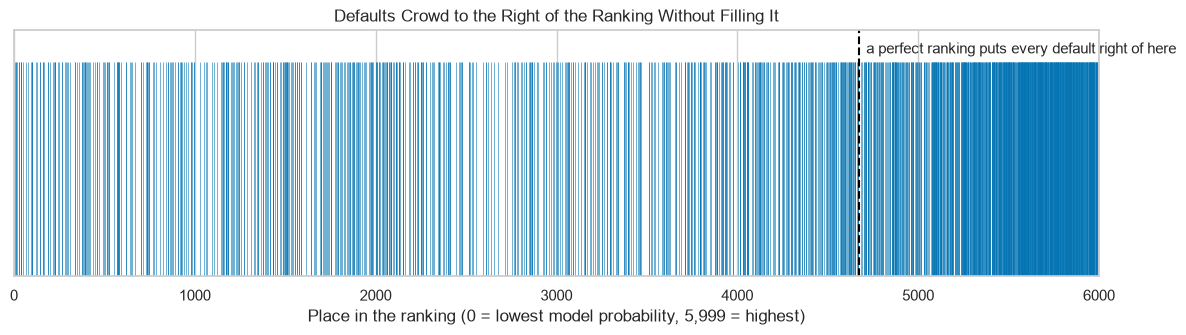

In [22]:
# the barcode: one thin tick per default at its place in the ranking
plt.figure(figsize=(14, 3.2))
plt.vlines(places, 0, 1, color=CELL_COLOURS["TP"], linewidth=0.4)
plt.axvline(6000 - 1327, color="black", linestyle="--")
plt.text(6000 - 1327 + 40, 1.04, "a perfect ranking puts every default right of here", fontsize=11)
plt.xlim(0, 6000)
plt.ylim(0, 1.15)
plt.yticks([])
plt.xlabel("Place in the ranking (0 = lowest model probability, 5,999 = highest)")
plt.title("Defaults Crowd to the Right of the Ranking Without Filling It")
plt.show()

949 of the 1,327 defaults sit in the upper half of the ranking and 378 in the lower half.

A perfect ranking would put all 1,327 in the last 1,327 places.

A threshold is one vertical cut through this row: everything right of it is flagged.

## Adding ROC AUC to the Scoring Function

Day 7's `model_performance_classification` with one line added: ROC AUC first, from the probabilities, so it reads no threshold.

In [23]:
# flag at or above the threshold, then ROC AUC and four measures in one row
def model_performance_classification(model, predictors, target, threshold=0.5):
    flags = (model.predict_proba(predictors)[:, 1] >= threshold).astype(int)
    return pd.DataFrame({
        "ROC AUC": [roc_auc_score(target, model.predict_proba(predictors)[:, 1])],
        "Accuracy": [accuracy_score(target, flags)],
        "Recall": [recall_score(target, flags, zero_division=0)],
        "Precision": [precision_score(target, flags, zero_division=0)],
        "F1": [f1_score(target, flags, zero_division=0)],
    })

In [24]:
# the model on the accounts it was fitted on, and on the validation accounts, at 0.5
train_valid = pd.concat([model_performance_classification(model, X_train, y_train).T,
                         model_performance_classification(model, X_valid, y_valid).T], axis=1)
train_valid.columns = ["training", "validation"]
train_valid

,training,validation
ROC AUC,0.7296,0.7190
Accuracy,0.8131,0.8123
Recall,0.2557,0.2442
Precision,0.7179,0.7248
F1,0.3770,0.3653


Every measure moves by 0.012 or less from training to validation.

**AUC says the ranking is well above a coin toss and far from perfect; it says nothing about where to cut it.**

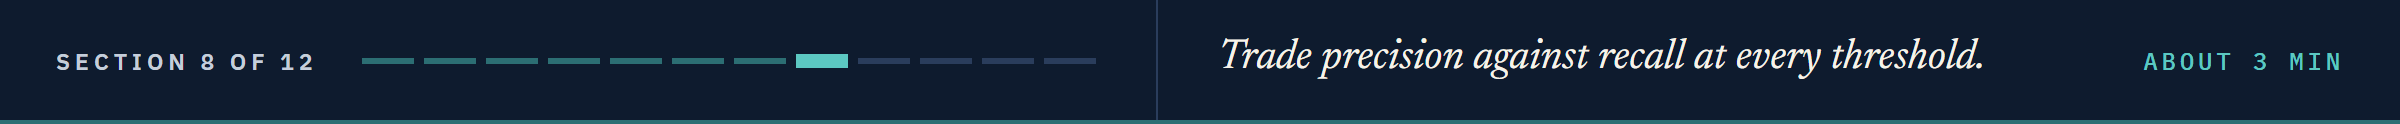

# The Precision-Recall Curve

## Precision Against Recall

`precision_recall_curve` gives Day 7's precision and recall at every threshold.

Q. How does precision fall as recall rises, and where does flagging everyone leave it?

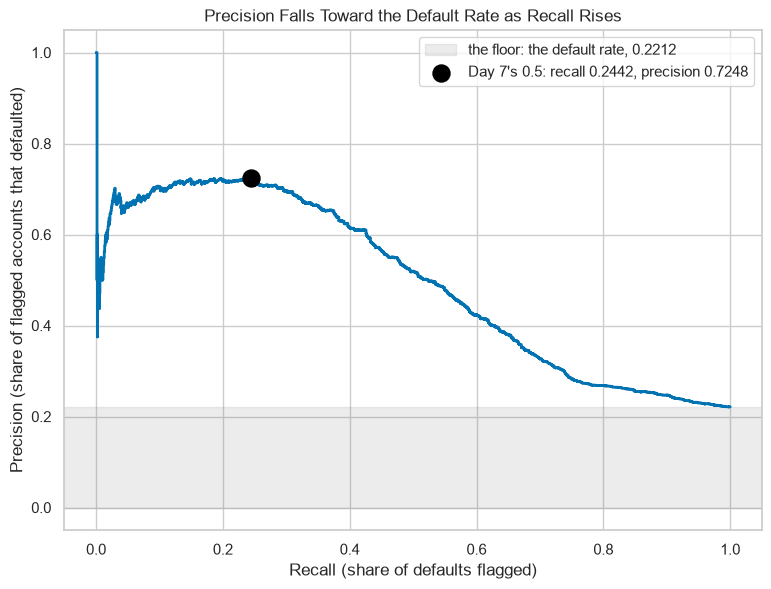

In [25]:
# precision and recall at every threshold
precision, recall, thresholds = precision_recall_curve(y_valid, proba_valid)

# the curve in steps, with the floor shaded: flag everyone and precision is the default rate
plt.figure(figsize=(9, 6.5))
plt.plot(recall, precision, drawstyle="steps-post", linewidth=2)  # steps-post: flat until the next point
plt.axhspan(0, y_valid.mean(), color="gray", alpha=0.15, label="the floor: the default rate, 0.2212")
plt.scatter(0.2442, 0.7248, s=150, color="black", zorder=3, label="Day 7's 0.5: recall 0.2442, precision 0.7248")
plt.xlabel("Recall (share of defaults flagged)")
plt.ylabel("Precision (share of flagged accounts that defaulted)")
plt.title("Precision Falls Toward the Default Rate as Recall Rises")
plt.legend(loc="upper right")
plt.show()

**Average precision** scores this curve in one number: each rise in recall times the precision there, added up.

In [26]:
# average precision is a step sum; auc() adds up trapezoids, joining the points with sloped lines instead
print(f"Average precision: {average_precision_score(y_valid, proba_valid):.4f}")
print(f"Trapezoid area:    {auc(recall, precision):.4f}")

Average precision: 0.4946
Trapezoid area:    0.4940


0.4946 as steps, 0.4940 as trapezoids: scikit-learn uses the steps, because a straight line between two points is a list no threshold makes.

## Balanced Rows

Q. If the validation accounts held as many paid accounts as defaults, which curve would move?

In [27]:
# every default, plus 1,327 paid accounts drawn with the seed
balanced = pd.concat([scores[scores["defaulted"] == 1], scores[scores["defaulted"] == 0].sample(n=1327, random_state=SEED)])
print("Accounts:", len(balanced), " Default rate:", balanced["defaulted"].mean())
print(f"ROC AUC: {roc_auc_score(balanced['defaulted'], balanced['proba']):.4f}  Average precision: {average_precision_score(balanced['defaulted'], balanced['proba']):.4f}")

Accounts: 2654  Default rate: 0.5
ROC AUC: 0.7158  Average precision: 0.7396


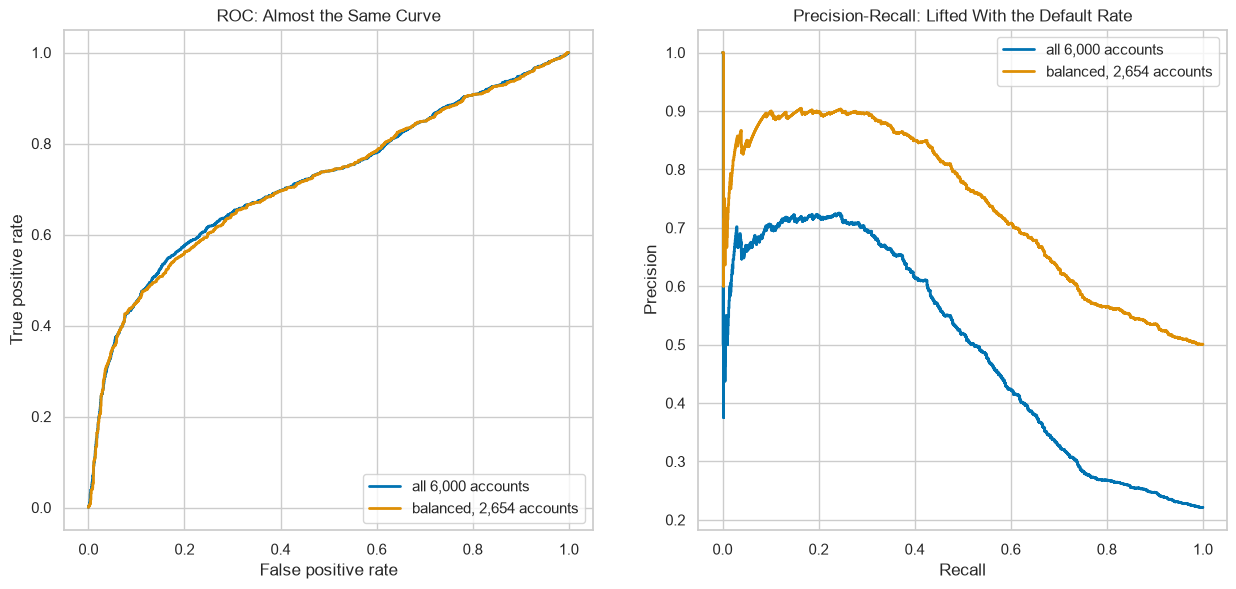

In [28]:
# small multiples: the ROC curves on the left, the precision-recall curves on the right
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 6.5))
for rows_used, name in [(scores, "all 6,000 accounts"), (balanced, "balanced, 2,654 accounts")]:
    rows_fpr, rows_tpr, _ = roc_curve(rows_used["defaulted"], rows_used["proba"])
    rows_precision, rows_recall, _ = precision_recall_curve(rows_used["defaulted"], rows_used["proba"])
    left.plot(rows_fpr, rows_tpr, linewidth=2, label=name)
    right.plot(rows_recall, rows_precision, drawstyle="steps-post", linewidth=2, label=name)
left.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC: Almost the Same Curve")
right.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall: Lifted With the Default Rate")
left.legend(loc="lower right")
right.legend(loc="upper right")
plt.show()

ROC AUC barely moves, 0.7190 to 0.7158, while average precision jumps from 0.4946 to 0.7396.

The two ROC curves almost coincide: each rate reads one row, and a row does not care how big the other row is.

Precision reads the flagged column, so when defaults are half the accounts, every flagged list holds more of them.

**ROC scores the ranking; precision-recall says what the flags look like at this default rate. Neither picks a threshold.**

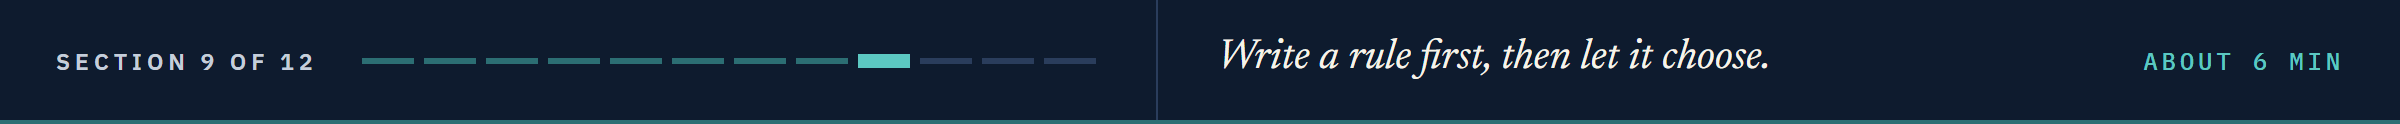

# Choosing a Threshold

## A Rule Written Down First

The course's rule: the highest threshold whose recall on the validation accounts is at least the target.

The target here is 0.70, as if the desk asked to see 70 percent of the defaults: a teaching convention, not a policy.

Writing the rule before trying thresholds keeps the numbers from talking us into one.

## Your Turn: Slide the Threshold

Find the highest threshold with recall of at least 0.70, and note how many accounts it flags.

In [29]:
# your turn: one slider moves one dot along both curves
def draw_point(threshold=0.5):
    tn, fp, fn, tp = confusion_matrix(y_valid, proba_valid >= threshold).ravel()
    fig, (left, right) = plt.subplots(1, 2, figsize=(14, 6))
    left.plot(fpr, tpr)
    left.scatter(fp / (fp + tn), tp / (tp + fn), s=160, color="black", zorder=3)
    right.plot(recall, precision, drawstyle="steps-post")
    right.scatter(tp / (tp + fn), tp / (tp + fp), s=160, color="black", zorder=3)
    left.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC at Threshold " + str(round(threshold, 2)))
    right.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall at Threshold " + str(round(threshold, 2)))
    plt.show()
    print("Flagged:", tp + fp, " TP:", tp, " FP:", fp, " Recall:", round(tp / (tp + fn), 4), " Precision:", round(tp / (tp + fp), 4))

interact(draw_point, threshold=(0.05, 0.95, 0.01));

interactive(children=(FloatSlider(value=0.5, description='threshold', max=0.95, min=0.05, step=0.01), Output()…

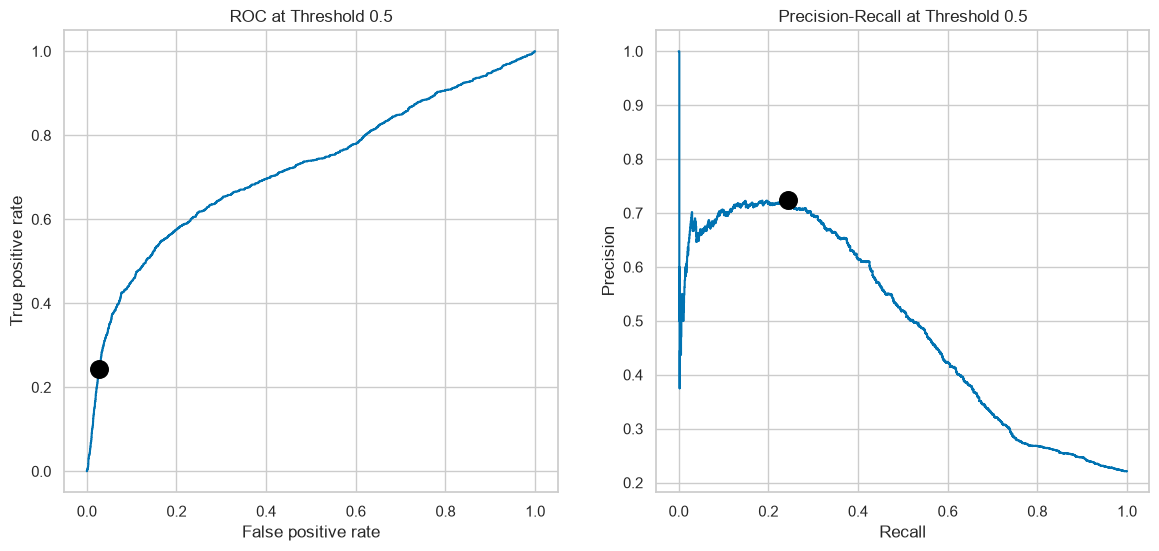

Flagged: 447  TP: 324  FP: 123  Recall: 0.2442  Precision: 0.7248


In [30]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_point(threshold=0.5)

At 0.5 the dot sits low on the ROC curve and high on the precision-recall curve: 447 flagged, recall 0.2442.

## The Rule in One Line

`recall` has one more entry than `thresholds`: its last, recall 0 at precision 1, belongs to no threshold, so `[:-1]` drops it.

In [31]:
# every threshold's precision and recall, then the highest threshold whose recall is at least 0.70
precision, recall, thresholds = precision_recall_curve(y_valid, proba_valid)
threshold_70 = thresholds[recall[:-1] >= 0.70].max()
print("Threshold:", round(threshold_70, 4))

Threshold: 0.2025


In [32]:
# the rule's flags, and the recall one distinct probability higher
flags_70 = (proba_valid >= threshold_70).astype(int)
print("Flagged:", flags_70.sum(), " Recall:", round(recall_score(y_valid, flags_70), 4), " Precision:", round(precision_score(y_valid, flags_70), 4))
next_up = thresholds[thresholds > threshold_70].min()
print("Recall one step higher:", round(recall_score(y_valid, proba_valid >= next_up), 4))

Flagged: 2843  Recall: 0.7001  Precision: 0.3268
Recall one step higher: 0.6993


The rule lands on 0.2025: 2,843 accounts flagged, recall 0.7001, precision 0.3268.

One distinct probability higher, recall drops to 0.6993, so this is the last threshold that meets the target.

About one flag in three is a default.

## Where Precision Meets Recall

**Predict 3**

Q. At one threshold precision equals recall. How many accounts does that threshold flag?

In [33]:
# the threshold where precision and recall are closest (.argmin() gives the position of the smallest value)
closest = abs(precision[:-1] - recall[:-1]).argmin()
crossing = thresholds[closest]
print(f"Threshold: {crossing:.4f}  Precision: {precision[closest]:.4f}  Recall: {recall[closest]:.4f}")
print("Flagged:", (proba_valid >= crossing).sum())

Threshold: 0.2610  Precision: 0.5079  Recall: 0.5079
Flagged: 1327


1,327 flagged, exactly as many as the defaults.

Precision is TP over the flagged accounts and recall is TP over the defaults, so the two are equal only when those counts are.

## Youden's J

**Youden's J** is the true positive rate minus the false positive rate: the curve's height above the diagonal.

Q. Which threshold lifts the ROC curve furthest above the diagonal?

In [34]:
# J at every threshold, and the threshold where it is largest (.argmax() gives its position)
j = tpr - fpr
youden = roc_thresholds[j.argmax()]
print("Threshold:", round(youden, 4), " J:", round(j.max(), 4), " Flagged:", (proba_valid >= youden).sum())

Threshold: 0.2475  J: 0.3829  Flagged: 1507


J is largest at 0.2475.

"Optimal" here means optimal for J, which adds the two rates as if a missed default and a false flag weighed the same within their own rows.

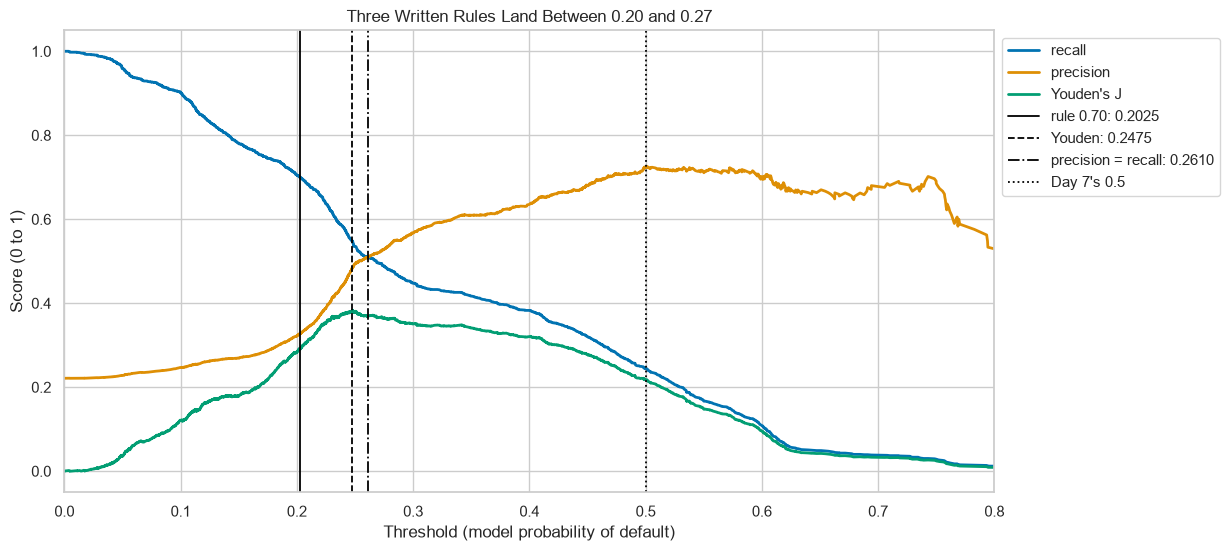

In [35]:
# recall, precision and J against the threshold, with the four candidates marked
plt.figure(figsize=(12, 6))
plt.plot(thresholds, recall[:-1], linewidth=2, label="recall")
plt.plot(thresholds, precision[:-1], linewidth=2, label="precision")
plt.plot(roc_thresholds[1:], j[1:], linewidth=2, label="Youden's J")
for value, name, style in [(threshold_70, "rule 0.70: 0.2025", "-"), (youden, "Youden: 0.2475", "--"), (crossing, "precision = recall: 0.2610", "-."), (0.5, "Day 7's 0.5", ":")]:
    plt.axvline(value, color="black", linestyle=style, linewidth=1.3, label=name)
plt.xlim(0, 0.8)
plt.xlabel("Threshold (model probability of default)")
plt.ylabel("Score (0 to 1)")
plt.title("Three Written Rules Land Between 0.20 and 0.27")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))  # the key just outside the top right corner
plt.show()

Recall falls and precision rises as the threshold moves right.

J peaks between the rule and the crossing.

**Three written rules land between 0.20 and 0.27; Day 7's 0.5 sits far to the right of all of them.**

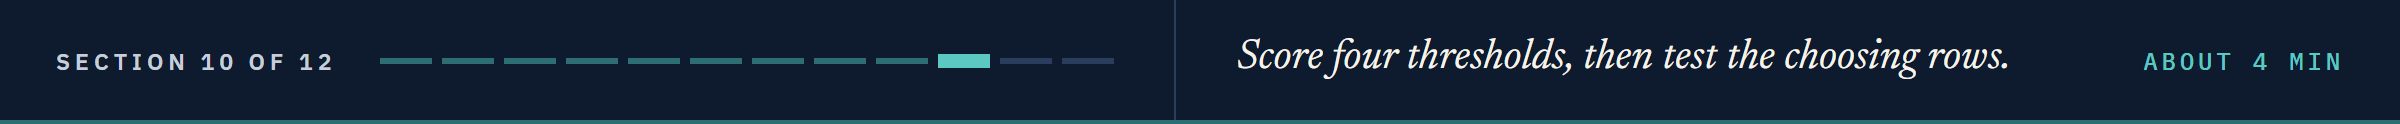

# Model Performance Comparison

## The Four Candidates

### Training Against Validation

Q. How do the four candidates score, on training and on validation accounts?

In [36]:
# the four candidate thresholds, by name
choices = {"0.5": 0.5, "rule 0.70": threshold_70, "Youden": youden, "precision = recall": crossing}

# training performance: one column per threshold
train_comp = pd.concat([model_performance_classification(model, X_train, y_train, t).T for t in choices.values()], axis=1)
train_comp.columns = list(choices)
train_comp

,0.5,rule 0.70,Youden,precision = recall
ROC AUC,0.7296,0.7296,0.7296,0.7296
Accuracy,0.8131,0.6146,0.7736,0.7853
Recall,0.2557,0.7089,0.5686,0.5314
Precision,0.7179,0.3282,0.4898,0.5142
F1,0.3770,0.4487,0.5263,0.5227


In [37]:
# validation performance: one column per threshold
valid_comp = pd.concat([model_performance_classification(model, X_valid, y_valid, t).T for t in choices.values()], axis=1)
valid_comp.columns = list(choices)
valid_comp

,0.5,rule 0.70,Youden,precision = recall
ROC AUC,0.7190,0.7190,0.7190,0.7190
Accuracy,0.8123,0.6147,0.7707,0.7823
Recall,0.2442,0.7001,0.5494,0.5079
Precision,0.7248,0.3268,0.4837,0.5079
F1,0.3653,0.4456,0.5145,0.5079


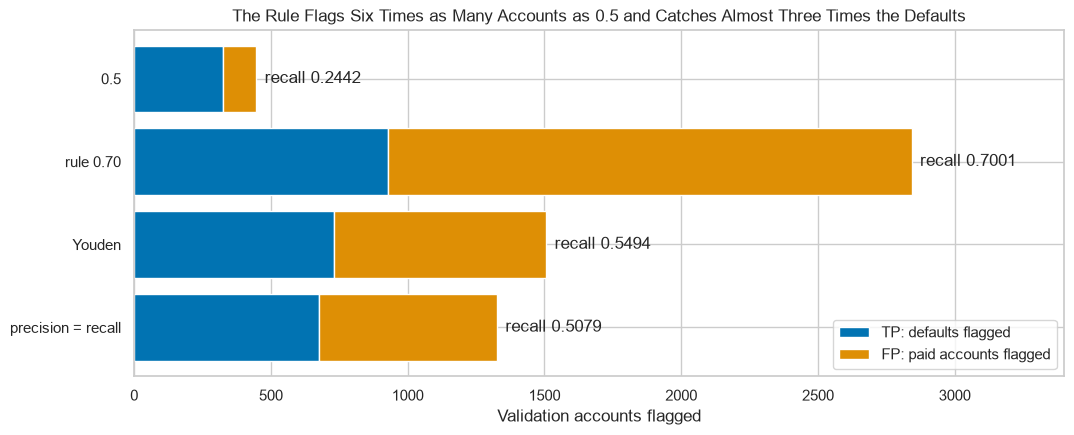

In [38]:
# stacked bars: the defaults each threshold flags (TP) and the paid accounts it flags (FP)
counts = pd.DataFrame([confusion_matrix(y_valid, proba_valid >= t).ravel() for t in choices.values()], index=list(choices), columns=["TN", "FP", "FN", "TP"])
plt.figure(figsize=(12, 4.5))
plt.barh(counts.index, counts["TP"], color=CELL_COLOURS["TP"], label="TP: defaults flagged")
plt.barh(counts.index, counts["FP"], left=counts["TP"], color=CELL_COLOURS["FP"], label="FP: paid accounts flagged")
for name, row in counts.iterrows():
    plt.text(row["TP"] + row["FP"] + 30, name, f"recall {row['TP'] / (row['TP'] + row['FN']):.4f}", va="center")
plt.gca().invert_yaxis()  # plt.gca() is the chart being drawn; inverted, 0.5 is the top row
plt.xlim(0, 3400)
plt.xlabel("Validation accounts flagged")
plt.title("The Rule Flags Six Times as Many Accounts as 0.5 and Catches Almost Three Times the Defaults")
plt.legend(loc="lower right")
plt.show()

Training and validation agree within 0.025 at every threshold.

ROC AUC is the same in every column: it reads no threshold.

The rule's accuracy, 0.6147, is below what flagging nobody scored on Day 7, and accuracy never chooses.

No threshold wins every row.

**We keep the rule, applied on validation accounts; on Day 10 the test accounts are opened once, to report.**

## Rows That Choose Cannot Report

### Twenty Halves of the Validation Accounts

`StratifiedShuffleSplit` cuts the validation accounts in half 20 times, each half with the same default rate.

On each cut one half chooses a threshold by the rule, and recall is read on both halves.

**Predict 4**

Q. In how many of the 20 cuts does recall on the other half fall below 0.70?

In [39]:
# 20 cuts: choose on one half by the rule, then read recall on both halves
halves = StratifiedShuffleSplit(n_splits=20, test_size=0.5, random_state=SEED)
cuts = []
for chooser, other in halves.split(X_valid, y_valid):
    half_precision, half_recall, half_thresholds = precision_recall_curve(y_valid.iloc[chooser], proba_valid[chooser])
    chosen = half_thresholds[half_recall[:-1] >= 0.70].max()
    cuts.append({"threshold": chosen, "half that chose": recall_score(y_valid.iloc[chooser], proba_valid[chooser] >= chosen),
                 "other half": recall_score(y_valid.iloc[other], proba_valid[other] >= chosen)})
cuts = pd.DataFrame(cuts)
print("Other half below 0.70:", (cuts["other half"] < 0.70).sum(), "of 20")

Other half below 0.70: 15 of 20


In [40]:
# the lowest and highest of each column over the 20 cuts
cuts.agg(["min", "max"])

,threshold,half that chose,other half
min,0.1941,0.7003,0.6395
max,0.2160,0.7014,0.7376


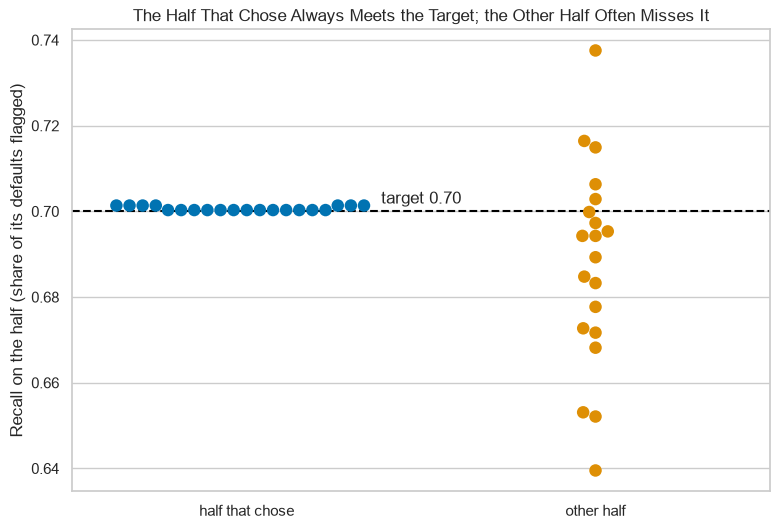

In [41]:
# a swarm of the 40 recalls: the half that chose against the other half
long = cuts.melt(value_vars=["half that chose", "other half"], var_name="half", value_name="recall")  # value_vars: the columns stacked, one row per recall
plt.figure(figsize=(9, 6))
sns.swarmplot(data=long, x="half", y="recall", hue="half", size=9, legend=False)
plt.axhline(0.70, color="black", linestyle="--")
plt.text(0.5, 0.701, "target 0.70", ha="center", va="bottom")
plt.xlabel("")
plt.ylabel("Recall on the half (share of its defaults flagged)")
plt.title("The Half That Chose Always Meets the Target; the Other Half Often Misses It")
plt.show()

The half that chose never drops below 0.70, by construction: the rule made it so.

The other half runs from 0.6395 to 0.7376, and the threshold itself moves from 0.1941 to 0.2160.

**Rows that choose a setting always look good on it; an honest number comes from rows that played no part.**

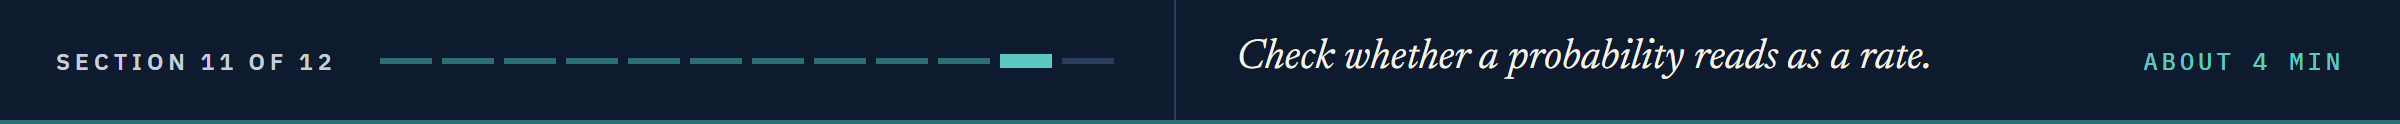

# Calibration

## The Top 100

In [42]:
# the 100 validation accounts with the highest model probability
top_100 = scores.sort_values("proba", ascending=False).head(100)
print("Average model probability:", round(top_100["proba"].mean(), 4))

Average model probability: 0.7788


**Predict 5**

Q. If those probabilities meant what they say, about 78 of the 100 would default. How many did?

In [43]:
# what happened to the top 100
print(top_100["defaulted"].sum(), "of the top 100 defaulted")

66 of the top 100 defaulted


66, not 78: at the top, the model's numbers run high.

## The Calibration Curve

A model is **calibrated** when accounts given 0.3 default about three times in ten.

`calibration_curve` sorts the accounts into 10 groups of 600 by probability (`strategy="quantile"`) and returns each group's share of defaults and mean probability.

A **reliability diagram** draws one against the other, beside the diagonal where they agree.

In [44]:
# each group's share of defaults and its mean model probability
observed, mean_proba = calibration_curve(y_valid, proba_valid, n_bins=10, strategy="quantile")
pd.DataFrame({"mean probability": mean_proba, "share defaulted": observed})

,mean probability,share defaulted
0,0.0416,0.1300
1,0.0812,0.1033
2,0.1133,0.1417
3,0.1458,0.1633
4,0.1820,0.0917
5,0.2077,0.1167
6,0.2272,0.1633
7,0.2512,0.2333
8,0.3573,0.3800
9,0.5800,0.6883


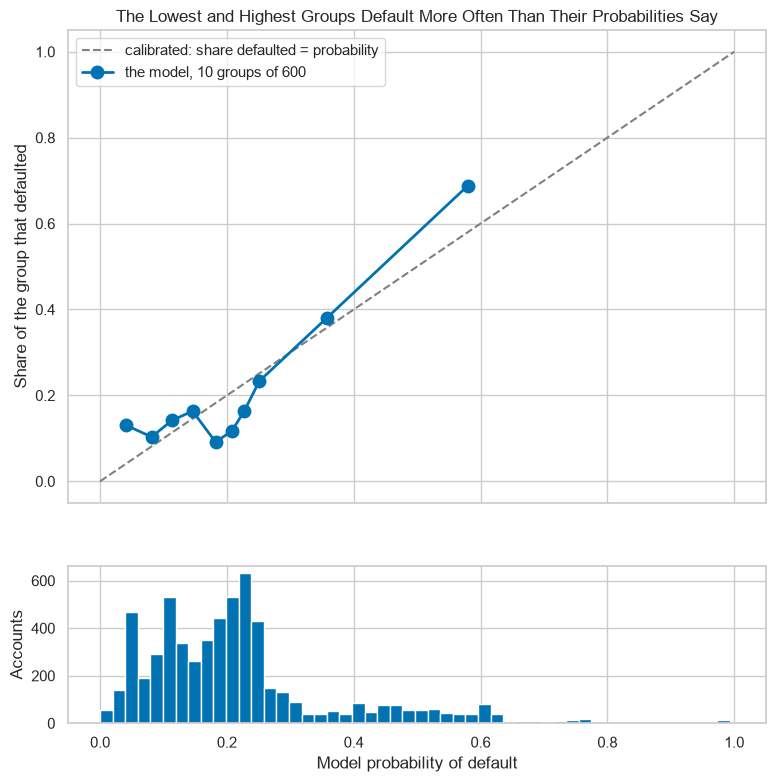

In [45]:
# the reliability diagram, with the spread of probabilities in a short panel beneath (height_ratios: the top panel three times as tall)
fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(9, 9), height_ratios=[3, 1])
top.plot([0, 1], [0, 1], color="gray", linestyle="--", label="calibrated: share defaulted = probability")
top.plot(mean_proba, observed, marker="o", markersize=9, linewidth=2, label="the model, 10 groups of 600")
top.set(ylabel="Share of the group that defaulted", title="The Lowest and Highest Groups Default More Often Than Their Probabilities Say")
top.legend(loc="upper left")
bottom.hist(proba_valid, bins=50)
bottom.set(xlabel="Model probability of default", ylabel="Accounts")
plt.show()

The group near 0.3, mean 0.3573, saw 38.0 percent defaults: close.

The lowest group says 0.0416 and 13.0 percent defaulted; the top group says 0.5800 and 68.8 percent did.

The four groups from 0.1820 to 0.2512 sit below the diagonal, and the one at 0.1820 saw only 9.2 percent.

At the very top it turns back: the top 100 said 0.7788 and 66 defaulted.

In [46]:
# squared probabilities: the same order, other numbers
observed_sq, mean_sq = calibration_curve(y_valid, proba_valid ** 2, n_bins=10, strategy="quantile")
print("Groups above the diagonal, as fitted:", (observed > mean_proba).sum(), " squared:", (observed_sq > mean_sq).sum())

Groups above the diagonal, as fitted: 6  squared: 10


Squaring kept AUC at 0.7190 and pushed 10 of 10 groups above the diagonal: AUC cannot see calibration.

Fixing the numbers themselves is Course 5's.

**The order is good enough to sort and to cut; not every probability reads as a rate.**

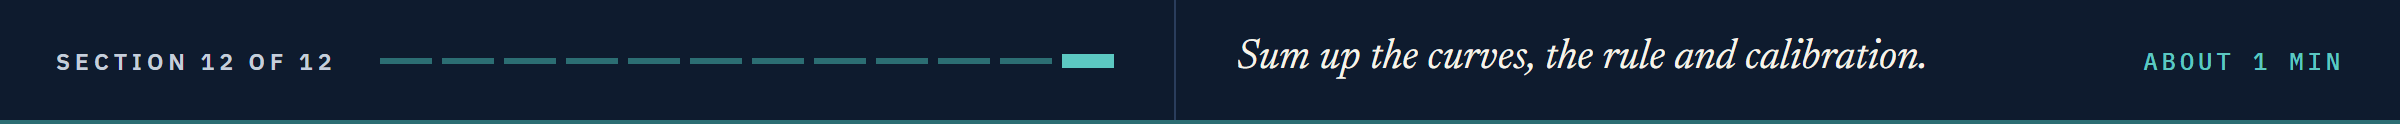

# Insights and Conclusion

The ROC curve holds every list the model can make: 5,883 thresholds on one line.

AUC, 0.7190, is the share of default and paid pairs ranked the right way, and only the order sets it.

The defaults crowd the top of the ranking without filling it.

Precision-recall moves with the default rate; ROC does not.

The rule, written first and applied on validation accounts, gives 0.2025: 2,843 flagged, recall 0.7001.

The probabilities rank better than they measure.

The validation scores describe 6,000 accounts in Taiwan in 2005, and no flag is a decision about a person.

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Draw a ROC curve by hand and with `roc_curve`, and read AUC as a share of pairs.
* Draw a precision-recall curve and say why it moves with the default rate.
* Choose a threshold on validation accounts by a rule written down first, with Youden's J beside it.
* Show why the accounts that choose a threshold cannot report its score.
* Read a reliability diagram.

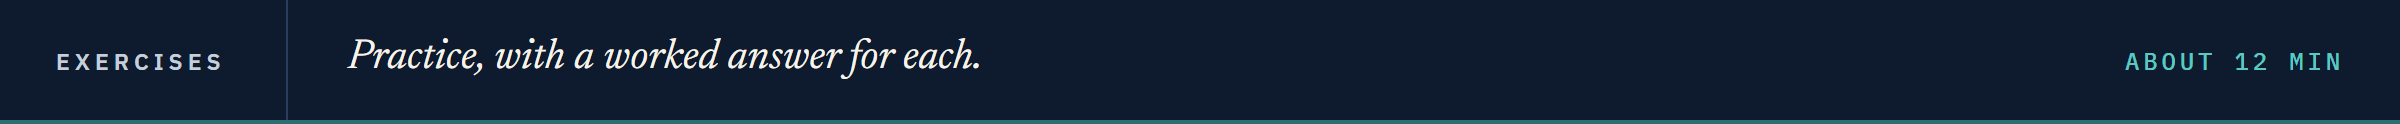

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [47]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**A Recall Target of 0.60**

Q. Apply the rule with a target of 0.60. Store the threshold in `ex1_threshold` and the precision of its flags on the validation accounts in `ex1_precision`.

In [48]:
# your code here
ex1_threshold = ...
ex1_precision = ...

In [49]:
check("Exercise 1 the threshold", ex1_threshold, 0.2338161639872026)
check("Exercise 1 the precision", ex1_precision, 0.423936170212766)

Exercise 1 the threshold: not attempted yet
Exercise 1 the precision: not attempted yet


### Exercise 2

**September Status Alone**

Q. Fit the same pipeline on `PAY_0` alone, on the training accounts, and store its ROC AUC on the validation accounts in `ex2_auc`.

In [50]:
# your code here
ex2_auc = ...

In [51]:
check("Exercise 2 the ROC AUC of PAY_0 alone", ex2_auc, 0.6833767908801561)

Exercise 2 the ROC AUC of PAY_0 alone: not attempted yet


### Exercise 3

**Youden's Threshold as a Function**

Q. Write `youden_threshold(target, proba)` that returns the threshold with the largest J, and test it with three `assert` lines: `[0, 0, 1, 1]` with `[0.1, 0.4, 0.35, 0.8]` gives 0.8, on the validation accounts it gives `youden`, and its answer is one of `proba_valid`. Store `youden_threshold(y_valid, proba_valid)` in `ex3_threshold`.

In [52]:
# your code here
ex3_threshold = ...

In [53]:
check("Exercise 3 Youden's threshold", ex3_threshold, 0.24746342840053667)

Exercise 3 Youden's threshold: not attempted yet


### Exercise 4: AI check

**The Threshold Chosen on the Wrong Accounts**

You asked an AI assistant for a function that chooses the threshold by the course's rule.

It runs, and the threshold it returns looks about right.

Test it, then find the one bug.

In [54]:
# the three parts of the split, by name
rows = {"train": (X_train, y_train), "valid": (X_valid, y_valid), "test": (X_test, y_test)}

In [55]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def choose_threshold(model, rows, target_recall=0.70):
    # choose on accounts the model has never seen, so the threshold is honest
    X_choose, y_choose = rows["test"]
    precision, recall, thresholds = precision_recall_curve(y_choose, model.predict_proba(X_choose)[:, 1])
    return thresholds[recall[:-1] >= target_recall].max()

print("Same as the rule on the validation accounts:", choose_threshold(model, rows) == threshold_70)

Same as the rule on the validation accounts: False


In [56]:
# the check the course's rule passes: the threshold is chosen on the validation accounts
assert choose_threshold(model, rows) == threshold_70, "the threshold was not chosen on the validation accounts"

AssertionError: the threshold was not chosen on the validation accounts

Q. Why does the check fail? Fix the one wrong line and store the fixed function's threshold in `ex4_threshold`.

In [57]:
# your code here
ex4_threshold = ...

In [58]:
check("Exercise 4 the fixed threshold", ex4_threshold, 0.20246382321769993)

Exercise 4 the fixed threshold: not attempted yet


## Congratulations!

You stopped taking 0.5 because it was the default.
You drew every list the model can make on one curve, proved on six million pairs what an AUC of 0.7190 means, and watched precision move with the default rate while ROC stood still.
Then you wrote a rule down first, chose on accounts set aside for choosing, and showed why those accounts cannot also report.
Days 9 and 10 choose in that same order, and you have now run it end to end.
In Day 9 you meet a model made of yes-or-no questions you can read: the decision tree.

[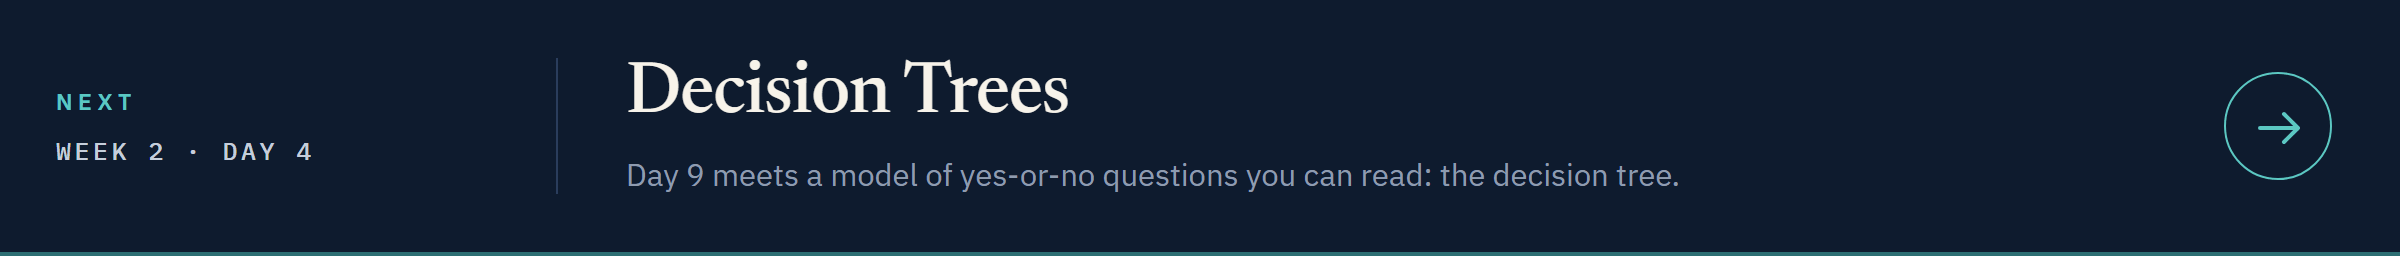](../day4/09_decision_trees.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week2/day4/09_decision_trees.ipynb)